# Phase 4 — Recorded places and unusual weeks in Gaza
**DS312, Group 7 | Historical ACLED snapshot | November 25, 2026**

## S1. What this notebook does
This notebook applies two methods taught by Ma'am Menorias to two different tables from Phase 2:

1. **DBSCAN (Module 7** groups nearby recorded event locations. Its input is **`data/processed/acled_focal_incidents.csv`**, where one row is one post-October 7 Gaza land focal event. The output is a list and map of recorded-place groups for source review (S3–S4).
2. **Isolation Forest (Module 9)** checks whether a completed district-week's counts look unusual compared with earlier weeks. Its input is **`data/processed/acled_district_week.csv`**, where one row is one district in one calendar week. A simpler earlier-week median rule is the comparison (S5–S6).

The other two CSVs support checks: **`acled_events_clean.csv`** verifies the event definition and provenance; **`acled_gaza_week.csv`** reconciles the Gaza-wide calendar totals. They are not extra training rows. These four tables overlap, so their row counts must never be added together. S2 traces each file and the timing; S7 gives findings and recommendations.

A group or flag is a lead for documentary review, not a verified incident footprint, anomaly, forecast, or legal conclusion.


## S2. Exactly which data goes into each step?
All four files were produced in Phase 2 and are read from `data/processed/`. Phase 3's data guide and Task 7 explain the original definitions. Table 3 below reports the checked row counts.

| File | What one row means | Phase 4 use | Enters a model? |
|---|---|---|---|
| `acled_events_clean.csv` | One Gaza-coded event in the source period; includes coast and earlier years | Check the focal-event rule, dates, districts and source IDs | No |
| `acled_gaza_week.csv` | One Gaza-wide calendar week, including weeks with zero events | Reconcile weekly totals and the incomplete final week | No |
| `acled_district_week.csv` | One district in one calendar week, including zero counts | **S5 median screen and S6 Isolation Forest**: focal count, political count/share and earlier-week features | Yes, one district-week at a time |
| `acled_focal_incidents.csv` | One post-cutoff Gaza **land** focal event | **S3–S4 DBSCAN**: latitude, longitude and location precision; keep ID/source/note for review | Yes, one event location at a time |

**How the event table was made.** “Focal” requires a targeting flag and the exact `Civilians (Palestine)` label in either actor field. “Land” excludes location names starting `Coast of`. This is a coding rule. DBSCAN has 10,583 eligible event rows at 101 recorded coordinate pairs; 7,576 rows have the most precise location code. We compare both populations. For the weekly methods, we use the district-week table directly; we do not recalculate its rows from the focal-event file or combine them with Gaza-wide weeks. Political share is undefined when its denominator is zero.

**When a result is available.** A weekly flag is issued only after that week closes. The week starting September 27, 2025 is incomplete and excluded. The first 52 complete weeks establish history, the next 26 allow internal tuning, and the remaining 25 support a retrospective check (Table 1). Each rolling baseline uses only eligible earlier calendar weeks; missing weeks are not silently skipped. The historical snapshot was already explored in Phase 3, so this is not an untouched final test.

**Settings fixed before the later comparison.** Module 7's DBSCAN sweep uses radii 0.5, 0.75, 1, 1.25, 1.5, 2 and 3 km and minimum group sizes 10/50 on both location populations. The 1 km/50 map is a descriptive reference, not a claimed optimum. Module 9's weekly comparison uses 8/12/16 preceding weeks; counts are flagged when the absolute modified z-score exceeds 3.5, with a one-event floor for a flat count history. Flat shares remain unscored. The 12-week view is the prespecified reference. The optional forest uses earlier-only district fits, two small count-feature sets, and sample sizes 32/automatic; its cutoff is set from earlier tuning scores to target a manageable review list, then frozen. S3–S6 explain each method next to its results.


In [1]:
import os, sys, json, hashlib, platform
from pathlib import Path
os.environ.setdefault('OMP_NUM_THREADS','1')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import sklearn
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score
from IPython.display import display, Markdown
%matplotlib inline
ROOT=Path.cwd()
assert (ROOT/'data/processed').is_dir(), 'Run from project root'
OUT=ROOT/'task4 tasks/implementation'
SEED=42; EARTH_KM=6371.0088
plt.rcParams.update({'figure.dpi':115,'axes.titlesize':11,'axes.labelsize':10,'font.size':10})
pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',90)
def report(text): display(Markdown(text))
def table(df,name):
    print(name); display(df)
    df.to_csv(OUT/(name.split(':')[0].replace(' ','_')+'.csv'),index=False)
def figure(fig,name):
    fig.tight_layout();fig.savefig(OUT/(name+'.png'),dpi=140,bbox_inches='tight');plt.show()
protected=json.loads((OUT/'protected_hashes.json').read_text())
def verify_protected():
    assert all(hashlib.sha256((ROOT/Path(p)).read_bytes()).hexdigest()==v for p,v in protected.items()), 'Protected file changed'
verify_protected()
print('Runtime:',sys.version.split()[0], '| pandas',pd.__version__,'| numpy',np.__version__,'| sklearn',sklearn.__version__)
(OUT/'runtime.json').write_text(json.dumps({'python':sys.version,'executable':sys.executable,'pandas':pd.__version__,'numpy':np.__version__,'sklearn':sklearn.__version__,'seed':SEED},indent=2))
def load(name,dates):
    df=pd.read_csv(ROOT/'data/processed'/name,parse_dates=dates)
    for c in df.columns:
        if c in ['complete_week','history_eligible','political_activity_recorded','targeting_flagged','political_violence','focal_event','geo_precision_1','time_precision_1','coastal_location','land_spatial_eligible','district_missing','high_fatalities_review']:
            vals=df[c].astype(str);assert vals.isin(['True','False']).all();df[c]=vals.map({'True':True,'False':False}).astype(bool)
    for c in ['geo_precision','time_precision']:
        if c in df:
            assert df[c].isin([1,2,3]).all();df[c]=pd.Categorical(df[c],categories=[1,2,3],ordered=True)
    return df
master=load('acled_events_clean.csv',['event_date','month_start','week_start'])
gw=load('acled_gaza_week.csv',['week_start','week_end'])
dw=load('acled_district_week.csv',['week_start','week_end'])
inc=load('acled_focal_incidents.csv',['event_date','month_start','week_start'])
assert [x.shape for x in [master,gw,dw,inc]]==[(26664,43),(104,13),(520,14),(10583,45)]
assert master.admin1.eq('Gaza Strip').all() and master.event_id_cnty.is_unique
assert master.targeting_flagged.equals(master.civilian_targeting.eq('Civilian targeting'))
focal=master.targeting_flagged & (master.actor1.eq('Civilians (Palestine)')|master.actor2.eq('Civilians (Palestine)'))
assert master.focal_event.equals(focal)
assert master.political_violence.equals(master.disorder_type.str.split(';').apply(lambda a:'Political violence' in [s.strip() for s in a]))
assert master.loc[focal,'political_violence'].all()
assert master.coastal_location.equals(master.location.str.startswith('Coast of'))
post=master.event_date.ge('2023-10-07')
assert master.land_spatial_eligible.equals(post & focal & ~master.coastal_location)
assert inc.event_id_cnty.tolist()==master.loc[master.land_spatial_eligible,'event_id_cnty'].tolist()
assert np.allclose(inc[['latitude_rad','longitude_rad']],np.radians(inc[['latitude','longitude']]))
assert inc.latitude.between(-90,90).all() and inc.longitude.between(-180,180).all()
assert inc.geo_precision_1.equals(inc.geo_precision.eq(1))
for w,area in [(gw,'admin1'),(dw,'admin2')]:
    assert not w.duplicated([area,'week_start']).any()
    assert w.week_end.equals(w.week_start+pd.Timedelta(days=6))
    assert w.complete_week.equals(w.week_end.le('2025-09-30'))
    assert w.history_eligible.equals(w.complete_week & w.political_events.gt(0))
    assert np.allclose(w.focal_share,w.focal_events/w.political_events.where(w.political_events.gt(0)),equal_nan=True)
    assert w.focal_events.le(w.political_events).all()
    for _,g in w.groupby(area):
        g=g.sort_values('week_start');h=g.focal_events.where(g.history_eligible)
        assert g.week_start.diff().dropna().eq(pd.Timedelta(days=7)).all()
        for c,expected in [('focal_count_for_history',h),('previous_week_focal',h.shift(1)),('previous_four_weeks_focal',h.shift(1).rolling(4).sum())]:
            assert np.allclose(g[c],expected,equal_nan=True)
    source=master.loc[post & master[area].notna()]
    expected=source.groupby([area,'week_start']).agg(recorded_events=('event_id_cnty','size'),political_events=('political_violence','sum'),focal_events=('focal_event','sum'))
    actual=w.set_index([area,'week_start'])[expected.columns]
    assert actual.equals(expected.reindex(actual.index,fill_value=0).astype(actual.dtypes))
weeks=sorted(gw.loc[gw.complete_week,'week_start'])
TRAIN_END=weeks[51]; TUNE_END=weeks[77]; ASSESS_START=weeks[78]
def block(date): return 'history' if date<=TRAIN_END else ('tuning' if date<=TUNE_END else 'assessment')
dw['block']=dw.week_start.map(block)
blocks=pd.DataFrame([{'block':n,'start':min(v),'last_week_start':max(v),'weeks':len(v)} for n in ['history','tuning','assessment'] if (v:=[d for d in weeks if block(d)==n])])
table(blocks,'Table 1: Chronological blocks')
table(dw.loc[~dw.complete_week,['admin2','week_start','week_end','focal_events','political_events']],'Table 2: Excluded partial weeks')
pops=pd.DataFrame({'population':['Gaza master','Gaza weeks','District weeks','Land focal','Precision-1 land focal'],'rows':[len(master),len(gw),len(dw),len(inc),int(inc.geo_precision_1.sum())]})
table(pops,'Table 3: Population accounting')
print('Missing district focal post-cutoff:',int(master.loc[post & master.admin2.isna(),'focal_event'].sum()))
print('All input, reconciliation, eligibility and lag assertions passed.')

Runtime: 3.12.14 | pandas 3.1.1 | numpy 2.5.5 | sklearn 1.9.1


Table 1: Chronological blocks


,block,start,last_week_start,weeks
0,history,2023-10-07,2024-09-28,52
1,tuning,2024-10-05,2025-03-29,26
2,assessment,2025-04-05,2025-09-20,25


Table 2: Excluded partial weeks


,admin2,week_start,week_end,focal_events,political_events
103,Deir El Balah,2025-09-27,2025-10-03,21,26
207,Gaza City,2025-09-27,2025-10-03,40,78
311,Khan Yunis,2025-09-27,2025-10-03,14,22
415,North Gaza,2025-09-27,2025-10-03,0,0
519,Rafah,2025-09-27,2025-10-03,5,7


Table 3: Population accounting


,population,rows
0,Gaza master,26664
1,Gaza weeks,104
2,District weeks,520
3,Land focal,10583
4,Precision-1 land focal,7576


Missing district focal post-cutoff: 3
All input, reconciliation, eligibility and lag assertions passed.


**Input interpretation (Tables 1-3).** The last week starts September 27, 2025 and is incomplete; all five district rows are excluded from scoring. Zero counts remain in the calendar, but a zero political denominator makes a share undefined and its count ineligible as local history. The three post-cutoff focal events without districts remain in Gaza totals. Table 1 fixes the chronological dates before modeling.

## S3. DBSCAN: which recorded places group together?
**Course workflow (Menorias Module 7, §§7.4–7.6).** First, plot the distance to each record's 10th or 50th nearest neighbor (Figure 1). Next, run DBSCAN across several neighborhood radii and minimum group sizes (Tables 4–5). Then read the number of groups, the share called “noise,” and the silhouette for non-noise records together (Table 6). Finally, profile the groups using original place names and event records (S4, Tables 8–10). This is the same course sequence, adapted to geographic coordinates.

The input is **`acled_focal_incidents.csv`** only. DBSCAN's `eps` is the maximum neighbor distance and `min_samples` is the number of records needed within that distance, including the record itself. We convert latitude/longitude to radians and use haversine distance, so the radii in the figures and tables mean **kilometers on Earth**, not scaled customer-feature units. IDs and notes are kept for review but never used to calculate distance.

Many separate event rows share exactly the same recorded coordinate. To avoid a large duplicate distance calculation, we fit each unique coordinate once and weight it by its number of event rows; we checked that this agrees with an ordinary row-by-row fit at the 1 km/50 reference. Repeated locations can make the neighbor-distance curve zero for much of the data, so it may not reveal a clear best radius. “Noise” means ungrouped under a particular setting; it is not a verified error or harm label.


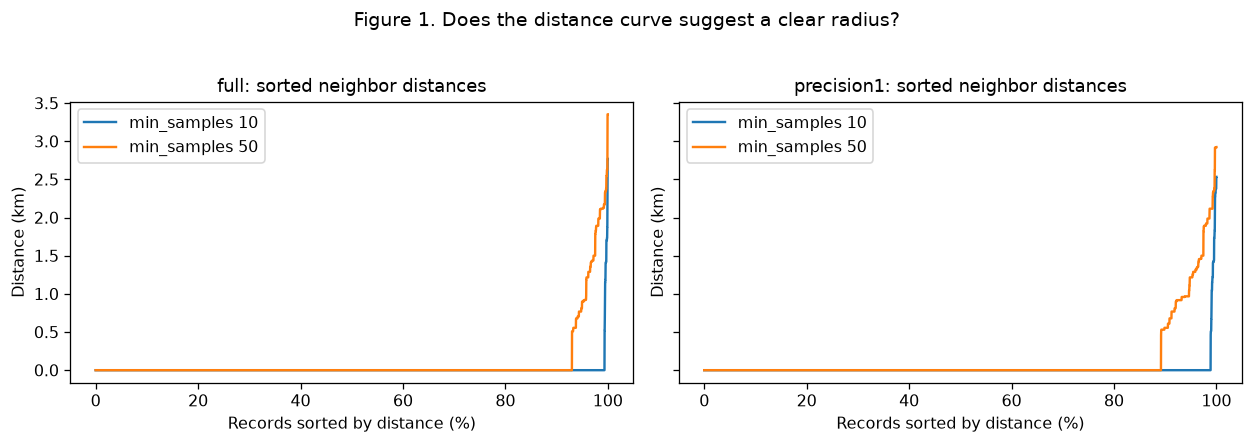

Table 4: Neighbor distance diagnostics


,population,min_samples,zero_distance_pct,p95_km,max_km
0,full,10,99.348011,0.000000,2.769620
1,full,50,92.988756,0.899247,3.353791
2,precision1,10,98.864836,0.000000,2.533836
3,precision1,50,89.176346,1.216400,2.924665


Table 5: Spatial candidate accounting


,population,radius_km,min_samples,records,coordinate_pairs,clusters,noise_records,noise_pct,smallest_cluster,median_cluster,largest_cluster
0,full,0.50,10,10583,101,81,67,0.633091,10,88.0,491
1,full,0.75,10,10583,101,74,62,0.585845,10,103.5,491
2,full,1.00,10,10583,101,58,58,0.548049,10,114.5,852
3,full,1.25,10,10583,101,42,49,0.463007,10,113.5,1295
4,full,1.50,10,10583,101,30,28,0.264575,10,134.0,2333
5,full,2.00,10,10583,101,19,10,0.094491,10,130.0,4484
6,full,3.00,10,10583,101,1,0,0.000000,10583,10583.0,10583
7,full,0.50,50,10583,101,55,740,6.992346,51,172.0,491
8,full,0.75,50,10583,101,54,583,5.508835,51,163.0,491
9,full,1.00,50,10583,101,43,447,4.223755,51,197.0,852


28 candidate fits; weighted/event-level reference partitions agree exactly in both populations.


**Figure 1 interpretation.** Zero-distance neighbors dominate where many events share a recorded place (Table 4); these are repeated records at coordinates, not duplicate event IDs. Table 5 shows how the group count and noise change across the frozen radii. Neither a high-density coordinate nor a curve bend validates an exact incident site.

In [2]:
RADII=[0.5,0.75,1.,1.25,1.5,2.,3.]; MIN_SAMPLES=[10,50]
populations={'full':inc.copy(),'precision1':inc.loc[inc.geo_precision_1].copy()}
assignments={}; spatial_rows=[]; kd_rows=[]
fig,axes=plt.subplots(1,2,figsize=(11,3.7),sharey=True)
for ax,(pop,d) in zip(axes,populations.items()):
    X=d[['latitude_rad','longitude_rad']].to_numpy()
    nn=NearestNeighbors(n_neighbors=50,metric='haversine',algorithm='ball_tree').fit(X)
    dist,_=nn.kneighbors(X)
    for m in MIN_SAMPLES:
        kdist=np.sort(dist[:,m-1]*EARTH_KM)
        ax.plot(np.linspace(0,100,len(kdist)),kdist,label=f'min_samples {m}')
        kd_rows.append({'population':pop,'min_samples':m,'zero_distance_pct':100*np.isclose(kdist,0,atol=1e-10).mean(),'p95_km':np.quantile(kdist,.95),'max_km':kdist.max()})
    ax.set(title=f'{pop}: sorted neighbor distances',xlabel='Records sorted by distance (%)',ylabel='Distance (km)');ax.legend()
fig.suptitle('Figure 1. Does the distance curve suggest a clear radius?',y=1.03)
figure(fig,'Figure_1_kdistance')
table(pd.DataFrame(kd_rows),'Table 4: Neighbor distance diagnostics')
def geo_fit(d,r,m):
    pairs=pd.MultiIndex.from_frame(d[['latitude_rad','longitude_rad']])
    inverse,unique=pd.factorize(pairs,sort=False)
    X=np.array(unique.tolist(),dtype=float); weights=np.bincount(inverse)
    lab=DBSCAN(eps=r/EARTH_KM,min_samples=m,metric='haversine',algorithm='ball_tree',n_jobs=1).fit_predict(X,sample_weight=weights)
    return lab[inverse]
for pop,d in populations.items():
    for m in MIN_SAMPLES:
        for r in RADII:
            labels=geo_fit(d,r,m)
            assignments[(pop,r,m)]=pd.Series(labels,index=d.event_id_cnty,name='cluster')
            sizes=pd.Series(labels[labels>=0]).value_counts()
            spatial_rows.append({'population':pop,'radius_km':r,'min_samples':m,'records':len(d),'coordinate_pairs':len(d[['latitude','longitude']].drop_duplicates()),'clusters':len(sizes),'noise_records':int((labels<0).sum()),'noise_pct':100*(labels<0).mean(),'smallest_cluster':int(sizes.min()) if len(sizes) else 0,'median_cluster':float(sizes.median()) if len(sizes) else 0,'largest_cluster':int(sizes.max()) if len(sizes) else 0})
            assert sizes.sum()+(labels<0).sum()==len(d)
spatial=pd.DataFrame(spatial_rows)
table(spatial,'Table 5: Spatial candidate accounting')
long_assign=pd.concat([s.rename('cluster').reset_index().assign(population=k[0],radius_km=k[1],min_samples=k[2]) for k,s in assignments.items()],ignore_index=True)
long_assign.to_csv(OUT/'spatial_assignments.csv',index=False)
assert len(long_assign)==sum(len(d)*len(RADII)*len(MIN_SAMPLES) for d in populations.values())
# Check weighted compression against the literal event fit at the reference setting.
from sklearn.metrics.cluster import contingency_matrix
for pop,d in populations.items():
    literal=DBSCAN(eps=1/EARTH_KM,min_samples=50,metric='haversine',algorithm='ball_tree',n_jobs=1).fit_predict(d[['latitude_rad','longitude_rad']])
    compressed=assignments[(pop,1.,50)].to_numpy()
    assert np.array_equal(literal<0,compressed<0)
    assert adjusted_rand_score(literal,compressed)==1.
print('28 candidate fits; weighted/event-level reference partitions agree exactly in both populations.')
report('**Figure 1 interpretation.** Zero-distance neighbors dominate where many events share a recorded place (Table 4); these are repeated records at coordinates, not duplicate event IDs. Table 5 shows how the group count and noise change across the frozen radii. Neither a high-density coordinate nor a curve bend validates an exact incident site.')

## S4. Does clustering add detail beyond district totals?
We compare neighboring settings by **co-membership Jaccard**: among event pairs grouped together by either setting, what fraction are grouped together by both? It ignores label numbers and does not count pairs of noise records as a group. Noise-status agreement is shown separately. This measures sensitivity, not accuracy against true labels.

Silhouette compares within-group and between-group distances; it is calculated only on non-noise records with at least two groups. To limit cost, use a uniform sample of up to 1,500 event records without replacement (seed 42), reporting represented groups. A group lost in sampling is not silently presented as fully evaluated. Dense repeated coordinates can produce high silhouettes even when radius sensitivity is substantial (Menorias Sections 7.5-7.6).

Table 6: Spatial evaluation with noise


,population,radius_km,min_samples,records,coordinate_pairs,clusters,noise_records,noise_pct,smallest_cluster,median_cluster,largest_cluster,silhouette,silhouette_n,groups_represented,silhouette_scope
0,full,0.50,10,10583,101,81,67,0.6331,10,88.0,491,0.9980,1500,78,sampled
1,full,0.75,10,10583,101,74,62,0.5858,10,103.5,491,0.9690,1500,71,sampled
2,full,1.00,10,10583,101,58,58,0.5480,10,114.5,852,0.8121,1500,57,sampled
3,full,1.25,10,10583,101,42,49,0.4630,10,113.5,1295,0.6421,1500,39,sampled
4,full,1.50,10,10583,101,30,28,0.2646,10,134.0,2333,0.5254,1500,30,sampled
5,full,2.00,10,10583,101,19,10,0.0945,10,130.0,4484,0.2823,1500,18,sampled
6,full,3.00,10,10583,101,1,0,0.0000,10583,10583.0,10583,NaN,1500,1,unavailable: fewer than two represented groups
7,full,0.50,50,10583,101,55,740,6.9923,51,172.0,491,1.0000,1500,55,sampled
8,full,0.75,50,10583,101,54,583,5.5088,51,163.0,491,0.9801,1500,54,sampled
9,full,1.00,50,10583,101,43,447,4.2238,51,197.0,852,0.8248,1500,43,sampled


Table 7: Membership sensitivity


,comparison,setting_a,setting_b,common_events,pair_jaccard,noise_status_agreement
0,neighbor radii,"('full', 0.5, 10)","('full', 0.75, 10)",10583,0.9478,0.9995
1,neighbor radii,"('full', 0.75, 10)","('full', 1.0, 10)",10583,0.6789,0.9996
2,neighbor radii,"('full', 1.0, 10)","('full', 1.25, 10)",10583,0.5557,0.9991
3,neighbor radii,"('full', 1.25, 10)","('full', 1.5, 10)",10583,0.5682,0.9980
4,neighbor radii,"('full', 1.5, 10)","('full', 2.0, 10)",10583,0.4355,0.9983
5,neighbor radii,"('full', 2.0, 10)","('full', 3.0, 10)",10583,0.2463,0.9991
6,neighbor radii,"('full', 0.5, 50)","('full', 0.75, 50)",10583,0.9460,0.9852
7,neighbor radii,"('full', 0.75, 50)","('full', 1.0, 50)",10583,0.6768,0.9871
8,neighbor radii,"('full', 1.0, 50)","('full', 1.25, 50)",10583,0.5548,0.9912
9,neighbor radii,"('full', 1.25, 50)","('full', 1.5, 50)",10583,0.5677,0.9941


Table 8: District count baseline


,admin2,records,places,share_pct
1,Gaza City,3436,25,32.47
2,Khan Yunis,2275,28,21.50
0,Deir El Balah,2264,14,21.39
3,North Gaza,1321,18,12.48
4,Rafah,1287,16,12.16


Table 9: Largest reference group profiles


C:\Users\USER\AppData\Local\Temp\ipykernel_27332\957370669.py:45: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  table(profiles.groupby('population',sort=False).head(6).round(2),'Table 9: Largest reference group profiles')


,population,cluster,records,districts,main_place,start,end,coordinate_pairs,repeated_coordinate_pct,precision1_pct
1,full,1,852,Gaza City,Gaza - Shujaiyya,2023-10-07,2025-09-30,4,99.53,79.34
0,full,0,771,Khan Yunis,Khan Yunis - West (Municipal Stadium),2023-10-07,2025-09-30,7,99.09,66.54
9,full,9,537,Rafah,Rafah,2023-10-07,2025-09-27,7,98.70,64.80
7,full,7,491,Gaza City,Gaza - Az Zaytun,2023-10-07,2025-09-30,1,99.80,83.30
11,full,11,440,Deir El Balah,An Nusayrat - Unspecified,2023-10-08,2025-09-30,1,99.77,89.55
8,full,8,435,North Gaza,Jabalya,2023-10-07,2025-09-12,1,99.77,82.07
44,precision1,1,676,Gaza City,Gaza - Shujaiyya,2023-10-07,2025-09-30,4,99.41,100.00
43,precision1,0,513,Khan Yunis,Khan Yunis - Unspecified,2023-10-07,2025-09-30,7,98.64,100.00
48,precision1,5,409,Gaza City,Gaza - Az Zaytun,2023-10-07,2025-09-30,1,99.76,100.00
52,precision1,9,394,Deir El Balah,An Nusayrat - Unspecified,2023-10-08,2025-09-30,1,99.75,100.00


Table 10: Documentary entry records


,population,cluster,event_id_cnty,event_date,admin2,location,event_type,source,records,notes_excerpt
1,full,1,PSE37614,2023-10-07,Gaza City,Gaza - Shujaiyya,Explosions/Remote violence,Palestine News and Information Agency,852,"On 7 October 2023, at approximately 14:47, Israeli warplanes conducted a number of rai..."
0,full,0,PSE37596,2023-10-07,Khan Yunis,Khan Yunis - West (Municipal Stadium),Explosions/Remote violence,Haaretz,771,"On 7 October 2023, Israeli warplanes conducted an airstrike in Khan Yunis (Khan Yunis ..."
44,precision1,1,PSE37614,2023-10-07,Gaza City,Gaza - Shujaiyya,Explosions/Remote violence,Palestine News and Information Agency,676,"On 7 October 2023, at approximately 14:47, Israeli warplanes conducted a number of rai..."
9,full,9,PSE37626,2023-10-07,Rafah,Rafah,Explosions/Remote violence,Palestine News and Information Agency,537,"On 7 October 2023, Israeli warplanes conducted an airstrike on a residential building ..."


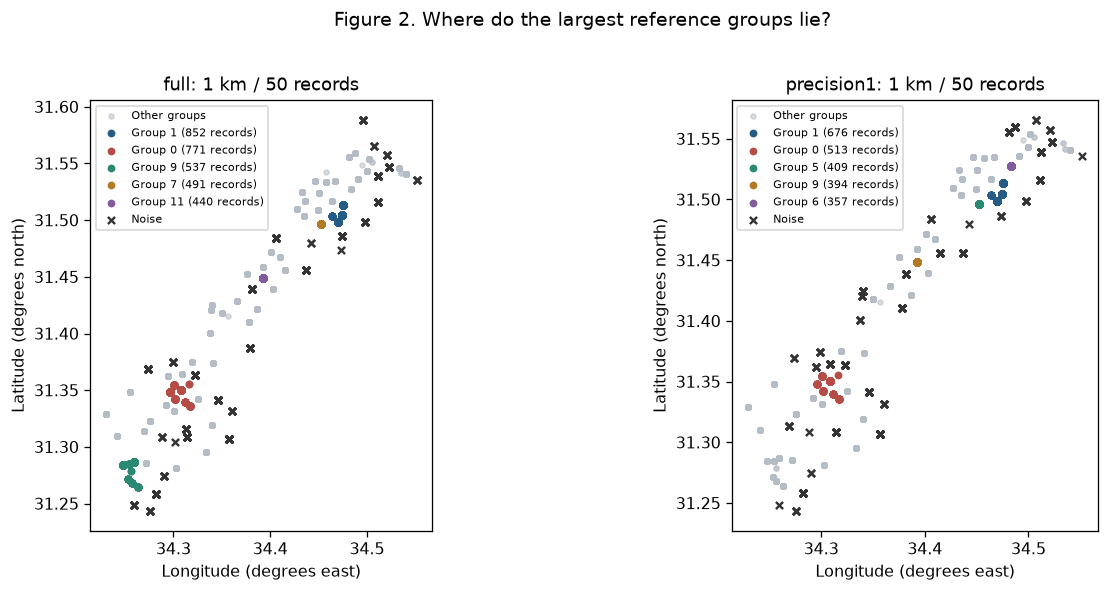

Table 11: Spatial time restriction


,period,start,end,records,clusters,noise_pct
0,earlier,2023-10-07,2024-10-04,5502,33,9.541985
1,later,2024-10-05,2025-09-30,5081,34,11.237945


Shared coordinate places: 84 | place-pair Jaccard: 0.773


**Figure 2 and Tables 6-11 interpretation.** At the prespecified 1 km/50 reference, 43 groups contain recorded land places; 4.2% of records are noise. At 3 km/50, 1 group remains, so radius materially changes the picture. The largest district is Gaza City (32.5% of land focal records); profiles split district totals into named-place groups, but repeated coordinates drive much of that detail. The two equal-duration spatial blocks share 84 coordinate places, with place-pair Jaccard 0.77; this is not event-level validation. No single robust or optimal partition is established. Use the reference groups only as traceable review bins, alongside district totals and the precision comparison. Full source excerpts are in cluster_source_examples.csv; no documentary outcomes have been verified.

In [3]:
def pair_jaccard(a,b):
    a=np.asarray(a);b=np.asarray(b)
    choose=lambda x:np.sum(np.asarray(x,dtype=float)*(np.asarray(x,dtype=float)-1)/2)
    pa=choose(pd.Series(a[a>=0]).value_counts());pb=choose(pd.Series(b[b>=0]).value_counts())
    mask=(a>=0)&(b>=0)
    inter=choose(pd.DataFrame({'a':a[mask],'b':b[mask]}).value_counts())
    return inter/(pa+pb-inter) if pa+pb-inter else np.nan
silrows=[]
for row in spatial.to_dict('records'):
    key=(row['population'],row['radius_km'],row['min_samples']);d=populations[key[0]]
    labels=assignments[key].to_numpy();idx=np.flatnonzero(labels>=0)
    chosen=np.random.default_rng(SEED).choice(idx,size=min(1500,len(idx)),replace=False)
    represented=len(np.unique(labels[chosen]));score=np.nan
    reason='one non-noise group' if row['clusters']<2 else 'sampled' if len(chosen)<len(idx) else 'all non-noise'
    if 2<=represented<len(chosen): score=silhouette_score(d[['latitude_rad','longitude_rad']].to_numpy()[chosen],labels[chosen],metric='haversine')
    else: reason='unavailable: fewer than two represented groups'
    silrows.append({**row,'silhouette':score,'silhouette_n':len(chosen),'groups_represented':represented,'silhouette_scope':reason})
spatial_eval=pd.DataFrame(silrows)
table(spatial_eval.round(4),'Table 6: Spatial evaluation with noise')
stability=[]
def compare(k1,k2,kind):
    a=assignments[k1];b=assignments[k2];ids=a.index.intersection(b.index);a=a.loc[ids].to_numpy();b=b.loc[ids].to_numpy()
    stability.append({'comparison':kind,'setting_a':str(k1),'setting_b':str(k2),'common_events':len(ids),'pair_jaccard':pair_jaccard(a,b),'noise_status_agreement':np.mean((a<0)==(b<0))})
for pop in populations:
    for m in MIN_SAMPLES:
        for a,b in zip(RADII[:-1],RADII[1:]):compare((pop,a,m),(pop,b,m),'neighbor radii')
    for r in RADII:compare((pop,r,10),(pop,r,50),'density')
for r in RADII:
    for m in MIN_SAMPLES:compare(('full',r,m),('precision1',r,m),'precision restriction')
stability=pd.DataFrame(stability)
table(stability.round(4),'Table 7: Membership sensitivity')
district_baseline=inc.groupby('admin2').agg(records=('event_id_cnty','size'),places=('location','nunique')).reset_index().sort_values('records',ascending=False)
district_baseline['share_pct']=100*district_baseline.records/len(inc)
table(district_baseline.round(2),'Table 8: District count baseline')
profiles=[]; examples=[]
for pop,d in populations.items():
    d=d.copy();d['cluster']=assignments[(pop,1.,50)].to_numpy()
    for label,g in d.loc[d.cluster>=0].groupby('cluster'):
        profiles.append({'population':pop,'cluster':label,'records':len(g),'districts':'; '.join(g.admin2.unique()),'main_place':g.location.mode().iloc[0],'start':g.event_date.min(),'end':g.event_date.max(),'coordinate_pairs':len(g[['latitude','longitude']].drop_duplicates()),'repeated_coordinate_pct':100*g.duplicated(['latitude','longitude']).mean(),'precision1_pct':100*g.geo_precision_1.mean()})
        # Earliest event provides a reproducible documentary entry, not an outcome judgment.
        e=g.sort_values(['event_date','event_id_cnty']).iloc[0]
        examples.append({'population':pop,'cluster':label,**e[['event_id_cnty','event_date','admin2','location','event_type','source','notes']].to_dict()})
profiles=pd.DataFrame(profiles).sort_values(['population','records'],ascending=[True,False]);examples=pd.DataFrame(examples)
profiles.to_csv(OUT/'all_cluster_profiles.csv',index=False);examples.to_csv(OUT/'cluster_source_examples.csv',index=False)
table(profiles.groupby('population',sort=False).head(6).round(2),'Table 9: Largest reference group profiles')
show_examples=examples.merge(profiles[['population','cluster','records']],on=['population','cluster']).sort_values('records',ascending=False).head(4).copy()
show_examples['notes_excerpt']=show_examples.notes.str.slice(0,180)
table(show_examples.drop(columns='notes'),'Table 10: Documentary entry records')
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,(pop,d) in zip(axes,populations.items()):
    d=d.copy();d['cluster']=assignments[(pop,1.,50)].to_numpy()
    top=profiles.loc[profiles.population.eq(pop)].head(5).cluster.tolist()
    other=d.loc[~d.cluster.isin(top)&d.cluster.ge(0)];ax.scatter(other.longitude,other.latitude,c='#b4bdc5',s=10,alpha=.5,label='Other groups')
    for color,label in zip(['#245c85','#b54c45','#2a8973','#b17b26','#825b9e'],top):
        g=d.loc[d.cluster.eq(label)];ax.scatter(g.longitude,g.latitude,s=15,color=color,label=f'Group {label} ({len(g)} records)')
    noise=d.loc[d.cluster.lt(0)];ax.scatter(noise.longitude,noise.latitude,s=20,marker='x',c='#333333',label='Noise')
    ax.set(title=f'{pop}: 1 km / 50 records',xlabel='Longitude (degrees east)',ylabel='Latitude (degrees north)');ax.set_aspect(1/np.cos(np.radians(31.4)));ax.legend(fontsize=7,loc='best')
fig.suptitle('Figure 2. Where do the largest reference groups lie?',y=1.02)
figure(fig,'Figure_2_reference_map')
# Different time periods have different event IDs: compare shared coordinate places instead.
MID=pd.Timestamp('2024-10-04')
time_labels=[];time_rows=[]
for name,mask in [('earlier',inc.event_date.le(MID)),('later',inc.event_date.gt(MID))]:
    d=inc.loc[mask].copy();d['cluster']=geo_fit(d,1.,50)
    coords=d[['latitude','longitude','cluster']].drop_duplicates().set_index(['latitude','longitude']).cluster
    time_labels.append(coords)
    time_rows.append({'period':name,'start':d.event_date.min(),'end':d.event_date.max(),'records':len(d),'clusters':d.loc[d.cluster.ge(0),'cluster'].nunique(),'noise_pct':100*d.cluster.lt(0).mean()})
shared=time_labels[0].index.intersection(time_labels[1].index)
time_j=pair_jaccard(time_labels[0].loc[shared],time_labels[1].loc[shared])
table(pd.DataFrame(time_rows),'Table 11: Spatial time restriction')
print('Shared coordinate places:',len(shared),'| place-pair Jaccard:',round(time_j,3))
ref=spatial_eval.query("population=='full' and radius_km==1 and min_samples==50").iloc[0]
wide=spatial_eval.query("population=='full' and radius_km==3 and min_samples==50").iloc[0]
near=stability.loc[stability.comparison.eq('neighbor radii') & stability.setting_a.isin([str(('full',.75,50)),str(('full',1.,50))])]
report(f'**Figure 2 and Tables 6-11 interpretation.** At the prespecified 1 km/50 reference, {int(ref.clusters)} groups contain recorded land places; {ref.noise_pct:.1f}% of records are noise. At 3 km/50, {int(wide.clusters)} group remains, so radius materially changes the picture. The largest district is {district_baseline.iloc[0].admin2} ({district_baseline.iloc[0].share_pct:.1f}% of land focal records); profiles split district totals into named-place groups, but repeated coordinates drive much of that detail. The two equal-duration spatial blocks share {len(shared)} coordinate places, with place-pair Jaccard {time_j:.2f}; this is not event-level validation. No single robust or optimal partition is established. Use the reference groups only as traceable review bins, alongside district totals and the precision comparison. Full source excerpts are in cluster_source_examples.csv; no documentary outcomes have been verified.')

**Spatial limitations.** One radius struggles with varying density, and dense recorded centroids can connect places into long chains: eps does not bound the whole group's diameter. Precision 1 is a selected subset, not exact impact coordinates or a random sample. High silhouette on repeated places does not demonstrate operational value. Table 7 shows neighborhood/density/precision sensitivity; Table 11 adds a descriptive time restriction. This comparison supports place-based review, not automatic hotspot intervention.

## S5. Which weeks differ from earlier local activity?
The simple baseline compares each completed district-week with its own preceding **8, 12 or 16 calendar weeks**, following Phase 3's local rule. The modified z-score is `0.6745 × (current − history median) / max(history MAD, 1)` for counts. MAD is the median absolute deviation from the history median; the one-event floor lets zero/flat count histories be scored without division by zero. A flag requires absolute score **greater than 3.5**. Positive means unusually high relative to recent local records; negative means unusually low.

For shares, use the same formula with the share MAD and **no one-event floor**; a zero MAD leaves the share unscored. Current and every preceding calendar week must be complete and have a positive political denominator. This preserves Phase 2's history rule, even when focal count is zero. Missing weeks are not skipped. Counts, denominators and shares stay beside every result. Counts and shares are different review signals, not independent corroborating labels.

The prespecified 12-week reference balances the shorter and longer windows; all three remain visible. Comparisons report both each setting's coverage and the common scored weeks, so extra alerts caused merely by extra coverage are distinguishable. Each baseline is available only after its current week closes. No future observation enters its median or MAD.

Table 12: Temporal coverage and exclusion reasons


,window,metric,reason,rows
0,8,focal_events,ineligible earlier calendar week,8
1,8,focal_events,insufficient earlier calendar weeks,40
2,8,focal_events,partial current week,5
3,8,focal_events,scored,465
4,8,focal_events,undefined current denominator,2
5,8,focal_share,ineligible earlier calendar week,8
6,8,focal_share,insufficient earlier calendar weeks,40
7,8,focal_share,partial current week,5
8,8,focal_share,scored,465
9,8,focal_share,undefined current denominator,2


Table 13: Focal count alert burden


,block,window,admin2,scored,high,low,alerts,alert_pct,common_scored,common_alerts
0,all,8,Deir El Balah,95,6,2,8,8.421053,87,8
1,all,8,Gaza City,95,9,4,13,13.684211,87,13
2,all,8,Khan Yunis,95,7,0,7,7.368421,87,7
3,all,8,North Gaza,85,9,3,12,14.117647,69,11
4,all,8,Rafah,95,5,3,8,8.421053,87,7
5,all,12,Deir El Balah,91,6,3,9,9.890110,87,9
6,all,12,Gaza City,91,6,0,6,6.593407,87,6
7,all,12,Khan Yunis,91,8,0,8,8.791209,87,8
8,all,12,North Gaza,77,7,0,7,9.090909,69,7
9,all,12,Rafah,91,3,1,4,4.395604,87,4


Table 14: Window alert overlap


,windows,common_scored,alerts_a,alerts_b,both,either,alert_jaccard
0,8 vs 12,441,48,34,23,59,0.390
1,12 vs 16,417,34,22,16,40,0.400
2,8 vs 16,417,46,22,14,54,0.259


... (3 outputs left out)

C:\Users\USER\AppData\Local\Temp\ipykernel_27332\2801816495.py:69: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  table(examples[['example','admin2','week_start','focal_events','political_events','focal_share','baseline','score','reason','direction','recent4_median','preceding4_median','trough_rebound_candidate']].round(3),'Table 16: Relative and absolute week examples')


,example,admin2,week_start,focal_events,political_events,focal_share,baseline,score,reason,direction,recent4_median,preceding4_median,trough_rebound_candidate
0,highest upward scores,Khan Yunis,2024-07-20,41,67,0.612,8.5,8.768,scored,high,10.5,6.0,False
1,highest upward scores,Khan Yunis,2024-07-27,32,60,0.533,9.0,7.757,scored,high,13.0,8.0,False
2,highest upward scores,Deir El Balah,2024-06-01,36,68,0.529,19.0,7.644,scored,high,16.5,23.0,False
3,lowest downward scores,Deir El Balah,2025-01-18,3,15,0.200,23.0,-6.745,scored,low,22.5,22.5,False
4,lowest downward scores,Deir El Balah,2025-01-25,5,6,0.833,23.0,-4.856,scored,low,22.5,22.5,False
5,high-count non-alerts,Gaza City,2025-09-13,84,113,0.743,54.0,2.381,scored,none,64.0,46.0,False
6,high-count non-alerts,Gaza City,2025-09-06,79,97,0.814,49.5,2.341,scored,none,53.5,50.5,False
7,high-count non-alerts,Gaza City,2025-09-20,77,131,0.588,58.0,1.114,scored,none,74.0,44.0,False
8,absolute peaks,Gaza City,2023-11-04,102,156,0.654,NaN,NaN,insufficient earlier calendar weeks,none,69.0,NaN,False
9,absolute peaks,Gaza City,2023-10-28,92,131,0.702,NaN,NaN,insufficient earlier calendar weeks,none,NaN,NaN,False


Table 17: Week documentary entry records


,example,admin2,week_start,event_id_cnty,event_date,location,source
0,highest upward scores,Khan Yunis,2024-07-20,PSE56289,2024-07-20,Abasan al Jadidah,Palestine News and Information Agency
1,highest upward scores,Khan Yunis,2024-07-20,PSE56293,2024-07-20,Bani Suheila,Quds News Network
2,highest upward scores,Khan Yunis,2024-07-27,PSE56716,2024-07-27,Bani Suheila,Newpress; Palestine News and Information Agency; Quds News Network; Twitter
3,highest upward scores,Khan Yunis,2024-07-27,PSE56729,2024-07-27,Khan Yunis - City Centre,Newpress; Quds News Network; Twitter
4,highest upward scores,Deir El Balah,2024-06-01,PSE53643,2024-06-01,Al Burayj,Arab 48; Palestine News and Information Agency; Quds News Network; Twitter
5,highest upward scores,Deir El Balah,2024-06-01,PSE53654,2024-06-01,An Nusayrat - North,Arab 48; Palestinian Ministry of Health; Quds News Network; Twitter
6,lowest downward scores,Deir El Balah,2025-01-18,PSE66976,2025-01-18,An Nusayrat - West,Liveuamap; Newpress; Quds News Network; Twitter
7,lowest downward scores,Deir El Balah,2025-01-18,PSE67132,2025-01-20,Deir al Balah Camp,The Independent Commission For Human Rights


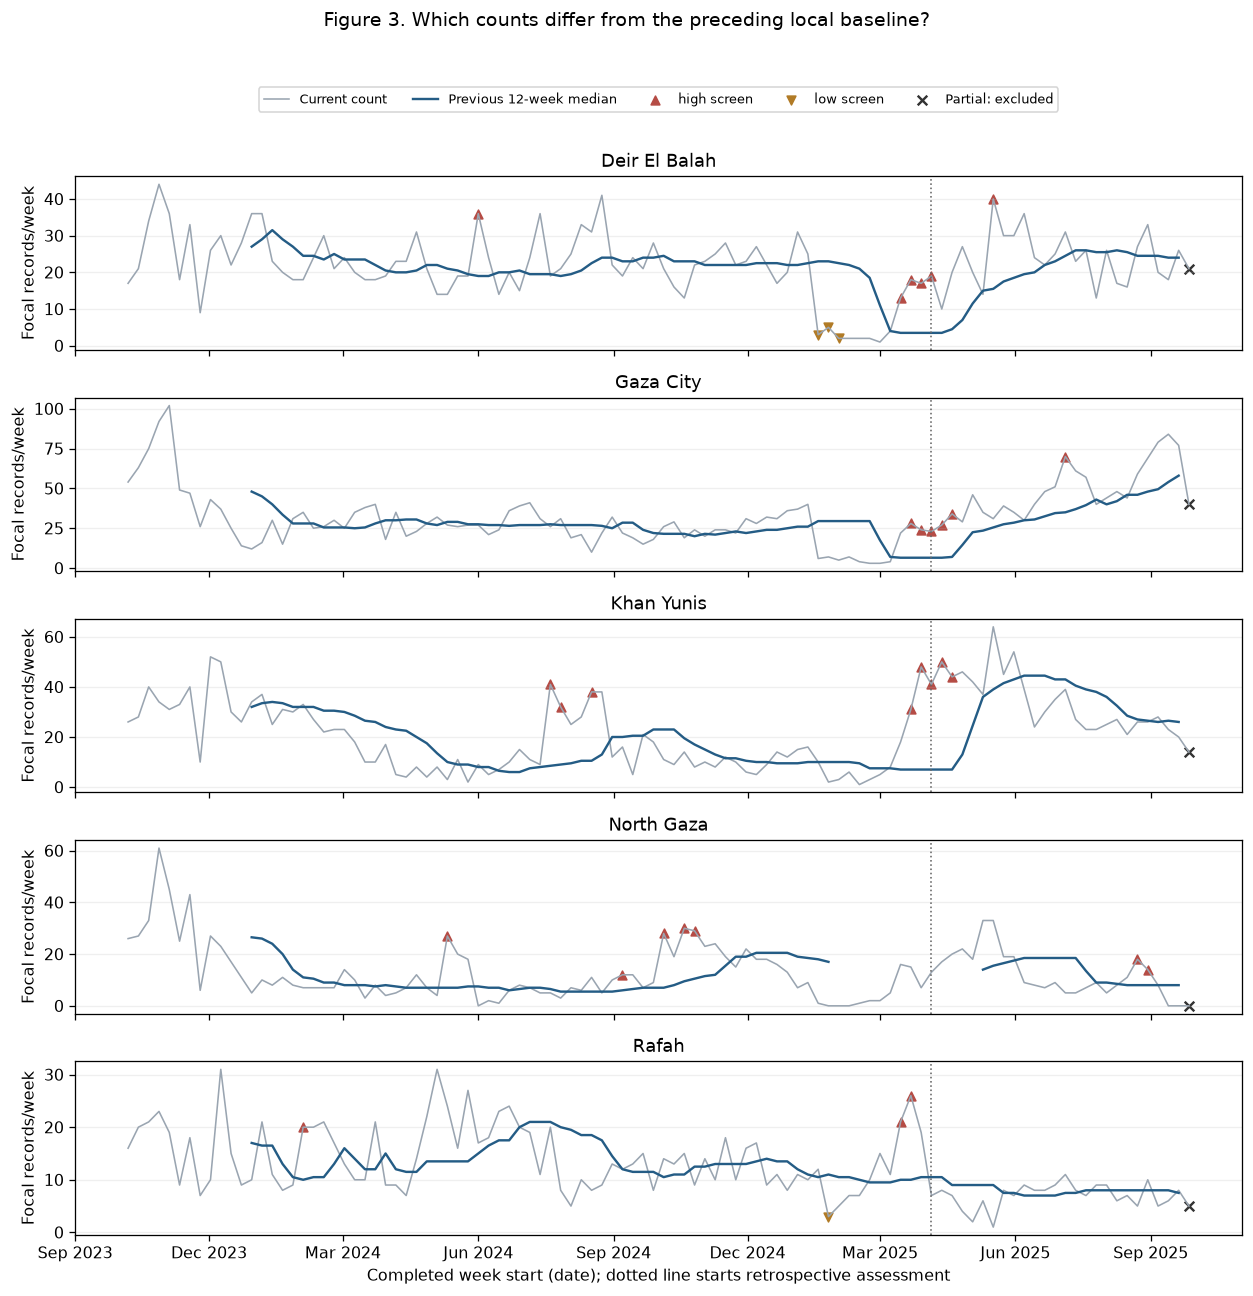

Table 18: Window summary


,window,scored,alerts,common_scored,alert_pct,common_alerts
0,8,465,48,417,10.32,46
1,12,441,34,417,7.71,34
2,16,417,22,417,5.28,22


Table 19: Share screening coverage


,window,scored,alerts
0,8,465,31
1,12,441,17
2,16,417,6


**Figure 3 and Tables 12-19 interpretation.** The same absolute count can be ordinary during a sustained high period and unusual after a trough. Red/amber markers flag departures in either direction; they are review leads, not verified anomalies. Table 16 separates the largest raw counts from relative-history alerts and provides high-count non-alert comparisons. Table 15 uses a declared descriptive tag: preceding four-week median at most max(1, one-quarter of the prior four-week median), followed by a current count above max(5, twice the recent median). It identifies possible rebounds for review, not verified recovery. Baseline gaps retain ineligible calendar history; the final partial week is displayed but unscored. Shares may remain unscored for flat histories even where counts can be screened. Table 17 and the accompanying CSVs link examples to original event sources; no source adjudication has been performed.

In [4]:
WINDOWS=[8,12,16]; Z_CUT=3.5
METRICS=['focal_events','political_events','focal_share']
def score_local(data,windows=WINDOWS):
    rows=[]
    for district,g in data.groupby('admin2',sort=True):
        g=g.sort_values('week_start').reset_index(drop=True)
        for w in windows:
            for i,row in g.iterrows():
                hist=g.iloc[max(0,i-w):i]
                for metric in METRICS:
                    median=mad=denom=z=np.nan
                    reason='scored'
                    if not row.complete_week:reason='partial current week'
                    elif row.political_events<=0:reason='undefined current denominator'
                    elif i<w:reason='insufficient earlier calendar weeks'
                    elif not hist.history_eligible.all():reason='ineligible earlier calendar week'
                    elif not np.isfinite(hist[metric]).all():reason='undefined history value'
                    if reason=='scored':
                        median=float(hist[metric].median());mad=float((hist[metric]-median).abs().median())
                        denom=max(mad,1.) if metric!='focal_share' else mad
                        if denom<=0:reason='flat share history'
                        else:z=.6745*(row[metric]-median)/denom
                    assert hist.empty or hist.week_start.max()<row.week_start
                    rows.append({'admin2':district,'week_start':row.week_start,'week_end':row.week_end,'block':row.block,'window':w,'metric':metric,'focal_events':row.focal_events,'political_events':row.political_events,'focal_share':row.focal_share,'previous_week_focal':row.previous_week_focal,'previous_four_weeks_focal':row.previous_four_weeks_focal,'baseline':median,'history_MAD':mad,'scale_used':denom,'score':z,'eligible':np.isfinite(z),'reason':reason,'alert':bool(abs(z)>Z_CUT) if np.isfinite(z) else False,'direction':'high' if z>Z_CUT else ('low' if z<-Z_CUT else 'none'),'history_start':hist.week_start.min() if len(hist) else pd.NaT,'history_end':hist.week_start.max() if len(hist) else pd.NaT})
    return pd.DataFrame(rows)
scores=score_local(dw)
assert scores.loc[scores.eligible,'history_end'].lt(scores.loc[scores.eligible,'week_start']).all()
# A future-data perturbation must not alter any earlier result.
changed=dw.copy();changed.loc[changed.week_start.ge(ASSESS_START),'focal_events']+=10000
check=score_local(changed)
assert np.allclose(scores.loc[scores.week_start.lt(ASSESS_START),'score'],check.loc[check.week_start.lt(ASSESS_START),'score'],equal_nan=True)
scores.to_csv(OUT/'temporal_scores.csv',index=False)
exclusions=scores.groupby(['window','metric','reason']).size().rename('rows').reset_index()
table(exclusions,'Table 12: Temporal coverage and exclusion reasons')
counts=scores.loc[scores.metric.eq('focal_events')].copy()
wide=counts.pivot(index=['admin2','week_start'],columns='window',values='score')
common=wide.dropna().index
counts['common_scored']=pd.MultiIndex.from_frame(counts[['admin2','week_start']]).isin(common)
burden=[]
for scope,mask in [('all',counts.week_start.notna()),('tuning',counts.block.eq('tuning')),('assessment',counts.block.eq('assessment'))]:
    for (w,d),g in counts.loc[mask].groupby(['window','admin2']):
        shared=g.loc[g.common_scored]
        burden.append({'block':scope,'window':w,'admin2':d,'scored':int(g.eligible.sum()),'high':int(g.direction.eq('high').sum()),'low':int(g.direction.eq('low').sum()),'alerts':int(g.alert.sum()),'alert_pct':100*g.alert.sum()/g.eligible.sum() if g.eligible.sum() else np.nan,'common_scored':len(shared),'common_alerts':int(shared.alert.sum())})
burden=pd.DataFrame(burden)
table(burden,'Table 13: Focal count alert burden')
overlap=[]
for a,b in [(8,12),(12,16),(8,16)]:
    paired=wide[[a,b]].dropna();fa=paired[a].abs().gt(Z_CUT);fb=paired[b].abs().gt(Z_CUT)
    overlap.append({'windows':f'{a} vs {b}','common_scored':len(paired),'alerts_a':int(fa.sum()),'alerts_b':int(fb.sum()),'both':int((fa&fb).sum()),'either':int((fa|fb).sum()),'alert_jaccard':(fa&fb).sum()/(fa|fb).sum() if (fa|fb).any() else np.nan})
table(pd.DataFrame(overlap).round(3),'Table 14: Window alert overlap')
# Transparent trough/rebound tag for interpretation; not an anomaly label.
recovery=[]
for district,g in dw.groupby('admin2'):
    g=g.sort_values('week_start');h=g.focal_events.where(g.history_eligible)
    recent=h.shift(1).rolling(4).median();older=h.shift(5).rolling(4).median()
    tag=recent.le(np.maximum(1,older*.25)) & g.focal_events.gt(np.maximum(5,recent*2)) & g.history_eligible
    recovery.extend([{'admin2':district,'week_start':d,'recent4_median':r,'preceding4_median':o,'trough_rebound_candidate':bool(t)} for d,r,o,t in zip(g.week_start,recent,older,tag)])
counts=counts.merge(pd.DataFrame(recovery),on=['admin2','week_start'],validate='many_to_one')
rec=counts.loc[counts.direction.eq('high')].groupby('window').agg(high_alerts=('alert','size'),trough_rebound_candidates=('trough_rebound_candidate','sum')).reset_index()
table(rec,'Table 15: High alerts after low recent history')
refcount=counts.loc[counts.window.eq(12)].copy()
examples=pd.concat([
    refcount.loc[refcount.direction.eq('high')].nlargest(3,'score').assign(example='highest upward scores'),
    refcount.loc[refcount.direction.eq('low')].nsmallest(2,'score').assign(example='lowest downward scores'),
    refcount.loc[refcount.eligible & ~refcount.alert].nlargest(3,'focal_events').assign(example='high-count non-alerts'),
    refcount.loc[refcount.week_end.le('2025-09-30')].nlargest(2,'focal_events').assign(example='absolute peaks')
],ignore_index=True)
examples=examples.drop_duplicates(['admin2','week_start','example'])
table(examples[['example','admin2','week_start','focal_events','political_events','focal_share','baseline','score','reason','direction','recent4_median','preceding4_median','trough_rebound_candidate']].round(3),'Table 16: Relative and absolute week examples')
traces=[]
for row in examples.itertuples():
    g=master.loc[master.admin2.eq(row.admin2)&master.week_start.eq(row.week_start)&master.focal_event].sort_values(['event_date','event_id_cnty'])
    assert len(g)==row.focal_events
    for e in g.head(2).itertuples():
        traces.append({'example':row.example,'admin2':row.admin2,'week_start':row.week_start,'event_id_cnty':e.event_id_cnty,'event_date':e.event_date,'location':e.location,'source':e.source,'notes':e.notes})
traces=pd.DataFrame(traces);traces.to_csv(OUT/'temporal_source_examples.csv',index=False)
# Full incident membership gives every selected week an auditable record set.
keys=examples[['admin2','week_start']].drop_duplicates()
master.loc[master.focal_event].merge(keys,on=['admin2','week_start'],validate='many_to_one')[['admin2','week_start','event_id_cnty','event_date','location','source','notes']].to_csv(OUT/'selected_week_focal_records.csv',index=False)
table(traces.drop(columns='notes').head(8),'Table 17: Week documentary entry records')
fig,axes=plt.subplots(5,1,figsize=(11,11),sharex=True)
for ax,(district,g) in zip(axes,refcount.groupby('admin2',sort=True)):
    g=g.sort_values('week_start')
    ax.plot(g.week_start,g.focal_events,color='#9aa5b1',lw=1,label='Current count')
    ax.plot(g.week_start,g.baseline,color='#245c85',lw=1.5,label='Previous 12-week median')
    for direction,color,marker in [('high','#b54c45','^'),('low','#b17b26','v')]:
        part=g.loc[g.direction.eq(direction)];ax.scatter(part.week_start,part.focal_events,c=color,marker=marker,s=30,label=f'{direction} screen')
    partial=g.loc[g.reason.eq('partial current week')];ax.scatter(partial.week_start,partial.focal_events,c='#333333',marker='x',label='Partial: excluded')
    ax.axvline(ASSESS_START,color='#666666',ls=':',lw=1);ax.set(title=district,ylabel='Focal records/week');ax.grid(axis='y',alpha=.2)
axes[0].legend(ncol=5,fontsize=8,loc='upper center',bbox_to_anchor=(.5,1.55))
axes[-1].set_xlabel('Completed week start (date); dotted line starts retrospective assessment')
axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=3));axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
fig.suptitle('Figure 3. Which counts differ from the preceding local baseline?',y=1.02)
figure(fig,'Figure_3_temporal_baselines')
summary=counts.groupby('window').agg(scored=('eligible','sum'),alerts=('alert','sum'),common_scored=('common_scored','sum')).reset_index()
summary['alert_pct']=100*summary.alerts/summary.scored
summary['common_alerts']=[int(counts.loc[counts.window.eq(w)&counts.common_scored,'alert'].sum()) for w in summary.window]
table(summary.round(2),'Table 18: Window summary')
share_summary=scores.loc[scores.metric.eq('focal_share')].groupby('window').agg(scored=('eligible','sum'),alerts=('alert','sum')).reset_index()
table(share_summary,'Table 19: Share screening coverage')
report('**Figure 3 and Tables 12-19 interpretation.** The same absolute count can be ordinary during a sustained high period and unusual after a trough. Red/amber markers flag departures in either direction; they are review leads, not verified anomalies. Table 16 separates the largest raw counts from relative-history alerts and provides high-count non-alert comparisons. Table 15 uses a declared descriptive tag: preceding four-week median at most max(1, one-quarter of the prior four-week median), followed by a current count above max(5, twice the recent median). It identifies possible rebounds for review, not verified recovery. Baseline gaps retain ineligible calendar history; the final partial week is displayed but unscored. Shares may remain unscored for flat histories even where counts can be screened. Table 17 and the accompanying CSVs link examples to original event sources; no source adjudication has been performed.')

In [5]:
episode_keys=counts.loc[counts.window.eq(8)&counts.direction.eq('high')&counts.week_start.between('2025-02-01','2025-04-30'),['admin2','week_start']]
episode=counts.merge(episode_keys,on=['admin2','week_start'],validate='many_to_one')
table(episode[['admin2','week_start','window','focal_events','political_events','baseline','history_MAD','score','direction','recent4_median','preceding4_median']].round(3),'Table 20: Early-2025 upward screens across windows')
report('**Table 20 interpretation.** These weeks are selected transparently because the eight-week screen flags an increase during February-April 2025; they are not a complete or independently labeled recovery set. Longer windows change the median/MAD and which weeks remain flagged. The narrow four-versus-four-week rebound tag in Table 15 matches none of the high alerts: it does not capture a prolonged trough when both preceding blocks are low. It is therefore not evidence that trough recovery is absent. Table 20 gives the actual counts and baselines for reviewing this sensitivity without relabeling events.')

Table 20: Early-2025 upward screens across windows


C:\Users\USER\AppData\Local\Temp\ipykernel_27332\1157438077.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  table(episode[['admin2','week_start','window','focal_events','political_events','baseline','history_MAD','score','direction','recent4_median','preceding4_median']].round(3),'Table 20: Early-2025 upward screens across windows')


,admin2,week_start,window,focal_events,political_events,baseline,history_MAD,score,direction,recent4_median,preceding4_median
0,Deir El Balah,2025-03-15,8,13,22,2.0,0.5,7.420,high,2.0,2.5
1,Deir El Balah,2025-03-22,8,18,35,2.0,0.5,10.792,high,3.0,2.0
2,Deir El Balah,2025-03-29,8,17,35,2.0,0.5,10.118,high,8.5,2.0
3,Deir El Balah,2025-04-05,8,19,31,3.0,1.5,7.195,high,15.0,2.0
4,Deir El Balah,2025-03-15,12,13,22,3.5,1.5,4.272,high,2.0,2.5
5,Deir El Balah,2025-03-22,12,18,35,3.5,1.5,6.520,high,3.0,2.0
6,Deir El Balah,2025-03-29,12,17,35,3.5,1.5,6.070,high,8.5,2.0
7,Deir El Balah,2025-04-05,12,19,31,3.5,1.5,6.970,high,15.0,2.0
8,Deir El Balah,2025-03-15,16,13,22,11.0,9.0,0.150,none,2.0,2.5
9,Deir El Balah,2025-03-22,16,18,35,9.0,7.5,0.809,none,3.0,2.0


**Table 20 interpretation.** These weeks are selected transparently because the eight-week screen flags an increase during February-April 2025; they are not a complete or independently labeled recovery set. Longer windows change the median/MAD and which weeks remain flagged. The narrow four-versus-four-week rebound tag in Table 15 matches none of the high alerts: it does not capture a prolonged trough when both preceding blocks are low. It is therefore not evidence that trough recovery is absent. Table 20 gives the actual counts and baselines for reviewing this sensitivity without relabeling events.

## S6. Isolation Forest: does a second weekly screen help?
**Course workflow (Menorias Module 9, §§3–6).** Give the forest a small table of numeric features, fit many random-splitting trees, score each row by how easily it is isolated, choose a review threshold, then inspect flagged rows against their original values. Tables 21–25 and Figure 4 follow those steps. The course example uses customer rows; here each row is a **completed district-week from `acled_district_week.csv`**.

We fit a separate forest for each district. A row contains the current focal count and the previous week's count; a second candidate also includes the preceding four-week total. These lag features describe recent context, as Module 9 recommends for time data. IDs, dates, notes and flags are excluded from predictors. We use 100 trees, seed 42 and two sample-size choices (32 or automatic). Counts are finite, so these tree models need no scaling or imputation.

The first 52 weeks supply training rows, with at least 40 eligible rows required. The next 26 weeks set a cutoff from the 90th percentile of anomaly scores: this is a **review workload**, not a claim that 10% of weeks are genuine anomalies. The smaller feature set is preferred; the sample-size choice nearest the tuning workload wins, with 32 breaking a tie. Both the model and cutoff are frozen before the later 25-week comparison. Table 23 compares forest and 12-week median flags on the *same assessable weeks*; Tables 24–25 return to raw counts and source records to interpret examples. Without independent review labels, agreement is not accuracy.


In [6]:
from sklearn.ensemble import IsolationForest
FEATURE_SETS={'count_lag1':['focal_events','previous_week_focal'],
              'count_lag1_prior4':['focal_events','previous_week_focal','previous_four_weeks_focal']}
if_models={}; if_candidates=[]; if_coverage=[]; if_tuning=[]
for district,g in dw.groupby('admin2',sort=True):
    g=g.sort_values('week_start')
    for feature_name,features in FEATURE_SETS.items():
        finite=np.isfinite(g[features]).all(axis=1)
        usable=g.history_eligible & finite
        train=g.loc[g.block.eq('history')&usable];tune=g.loc[g.block.eq('tuning')&usable]
        if_coverage.append({'admin2':district,'features':feature_name,'history_calendar_rows':int(g.block.eq('history').sum()),'training_rows':len(train),'tuning_calendar_rows':int(g.block.eq('tuning').sum()),'tuning_rows':len(tune),'excluded_history':int(g.block.eq('history').sum())-len(train),'excluded_tuning':int(g.block.eq('tuning').sum())-len(tune),'feasible':len(train)>=40 and len(tune)>=15})
        if len(train)<40 or len(tune)<15:continue
        assert train.week_start.max()<tune.week_start.min() and tune.week_start.max()<ASSESS_START
        for sample in [32,'auto']:
            name=feature_name+'__'+str(sample)
            model=IsolationForest(n_estimators=100,max_samples=sample,contamination='auto',random_state=SEED,n_jobs=1).fit(train[features])
            anomaly=-model.score_samples(tune[features]);cutoff=float(np.quantile(anomaly,.9,method='higher'))
            if_models[(district,name)]={'model':model,'features':features,'cutoff':cutoff,'training_rows':len(train),'train_end':train.week_start.max(),'calibration_end':tune.week_start.max()}
            rate=float(np.mean(anomaly>cutoff))
            if_candidates.append({'candidate':name,'admin2':district,'feature_count':len(features),'max_samples':str(sample),'training_rows':len(train),'tuning_rows':len(tune),'cutoff':cutoff,'tuning_alerts':int((anomaly>cutoff).sum()),'tuning_rate':rate})
            if_tuning.extend([{'admin2':district,'candidate':name,'week_start':d,'anomaly_score':s,'cutoff':cutoff,'alert':s>cutoff} for d,s in zip(tune.week_start,anomaly)])
table(pd.DataFrame(if_coverage),'Table 21: Forest history feasibility')
if_candidates=pd.DataFrame(if_candidates)
assert not if_candidates.empty,'No defensible comparison: record deferral instead'
table(if_candidates.round(4),'Table 22: Forest tuning candidates')
choice=if_candidates.groupby('candidate').agg(feature_count=('feature_count','first'),districts=('admin2','nunique'),mean_tuning_rate=('tuning_rate','mean')).reset_index()
choice['budget_distance']=(choice.mean_tuning_rate-.1).abs();choice['sample_tie']=choice.candidate.str.endswith('__32').map({True:0,False:1})
choice=choice.sort_values(['feature_count','budget_distance','sample_tie','candidate'])
SELECTED_IF=choice.iloc[0].candidate
(OUT/'forest_frozen_choice.json').write_text(json.dumps({'candidate':SELECTED_IF,'calibration_end':str(TUNE_END.date()),'assessment_start':str(ASSESS_START.date()),'criterion':'smallest feature set; tuning burden nearest 10%; tie max_samples 32','cutoffs':{d:v['cutoff'] for (d,n),v in if_models.items() if n==SELECTED_IF}},indent=2))
pd.DataFrame(if_tuning).to_csv(OUT/'forest_tuning_scores.csv',index=False)
report(f'**Frozen decision before assessment:** {SELECTED_IF}. Table 21 records actual feasible training and tuning sizes, including missing-lag/history exclusions. The calibration burden is a budget check, not model accuracy. Assessment will now be scored without changing these fits or cutoffs.')

Table 21: Forest history feasibility


,admin2,features,history_calendar_rows,training_rows,tuning_calendar_rows,tuning_rows,excluded_history,excluded_tuning,feasible
0,Deir El Balah,count_lag1,52,51,26,26,1,0,True
1,Deir El Balah,count_lag1_prior4,52,48,26,26,4,0,True
2,Gaza City,count_lag1,52,51,26,26,1,0,True
3,Gaza City,count_lag1_prior4,52,48,26,26,4,0,True
4,Khan Yunis,count_lag1,52,51,26,26,1,0,True
5,Khan Yunis,count_lag1_prior4,52,48,26,26,4,0,True
6,North Gaza,count_lag1,52,51,26,23,1,3,True
7,North Gaza,count_lag1_prior4,52,48,26,20,4,6,True
8,Rafah,count_lag1,52,51,26,26,1,0,True
9,Rafah,count_lag1_prior4,52,48,26,26,4,0,True


Table 22: Forest tuning candidates


,candidate,admin2,feature_count,max_samples,training_rows,tuning_rows,cutoff,tuning_alerts,tuning_rate
0,count_lag1__32,Deir El Balah,2,32,51,26,0.6699,0,0.0000
1,count_lag1__auto,Deir El Balah,2,auto,51,26,0.7045,0,0.0000
2,count_lag1_prior4__32,Deir El Balah,3,32,48,26,0.6627,0,0.0000
3,count_lag1_prior4__auto,Deir El Balah,3,auto,48,26,0.7011,0,0.0000
4,count_lag1__32,Gaza City,2,32,51,26,0.5980,0,0.0000
5,count_lag1__auto,Gaza City,2,auto,51,26,0.6305,0,0.0000
6,count_lag1_prior4__32,Gaza City,3,32,48,26,0.6054,0,0.0000
7,count_lag1_prior4__auto,Gaza City,3,auto,48,26,0.6245,0,0.0000
8,count_lag1__32,Khan Yunis,2,32,51,26,0.5511,2,0.0769
9,count_lag1__auto,Khan Yunis,2,auto,51,26,0.5808,2,0.0769


**Frozen decision before assessment:** count_lag1__32. Table 21 records actual feasible training and tuning sizes, including missing-lag/history exclusions. The calibration burden is a budget check, not model accuracy. Assessment will now be scored without changing these fits or cutoffs.

Table 23: Forest versus MAD on common assessment weeks


,candidate,admin2,assessment_calendar_rows,forest_scored,mad_scored,common_scored,forest_alerts,mad_alerts,both,forest_only,mad_only,neither,alert_jaccard
0,count_lag1__32,Deir El Balah,26,25,25,25,0,2,0,0,2,23,0.000
1,count_lag1__32,Gaza City,26,25,25,25,7,4,1,6,3,15,0.100
2,count_lag1__32,Khan Yunis,26,25,25,25,9,3,3,6,0,16,0.333
3,count_lag1__32,North Gaza,26,25,20,20,4,2,0,4,2,14,0.000
4,count_lag1__32,Rafah,26,25,25,25,7,0,0,7,0,18,0.000
5,count_lag1__auto,Deir El Balah,26,25,25,25,0,2,0,0,2,23,0.000
6,count_lag1__auto,Gaza City,26,25,25,25,3,4,0,3,4,18,0.000
7,count_lag1__auto,Khan Yunis,26,25,25,25,9,3,3,6,0,16,0.333
8,count_lag1__auto,North Gaza,26,25,20,20,4,2,0,4,2,14,0.000
9,count_lag1__auto,Rafah,26,25,25,25,8,0,0,8,0,17,0.000


Selected candidate assessment totals: {'common_scored': 120, 'forest_alerts': 27, 'mad_alerts': 11, 'both': 4, 'forest_only': 23, 'mad_only': 7, 'neither': 86}


Table 24: Forest comparison examples


C:\Users\USER\AppData\Local\Temp\ipykernel_27332\4196229063.py:31: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  table(if_examples[['category','admin2','week_start','focal_events','political_events','focal_share','previous_week_focal','anomaly_score','cutoff','mad_score','direction','baseline']].round(3),'Table 24: Forest comparison examples')


,category,admin2,week_start,focal_events,political_events,focal_share,previous_week_focal,anomaly_score,cutoff,mad_score,direction,baseline
0,Forest only,Gaza City,2025-09-13,84,113,0.743,79.0,0.700,0.598,2.381,none,54.0
1,Forest only,Gaza City,2025-09-20,77,131,0.588,84.0,0.696,0.598,1.114,none,58.0
2,Forest only,Gaza City,2025-09-06,79,97,0.814,69.0,0.666,0.598,2.341,none,49.5
3,MAD flagged,Deir El Balah,2025-04-05,19,31,0.613,17.0,0.449,0.670,6.970,high,3.5
4,MAD flagged,North Gaza,2025-08-23,18,24,0.750,11.0,0.478,0.553,6.745,high,8.0
5,Neither; high raw count,Gaza City,2025-08-23,59,94,0.628,44.0,0.561,0.598,1.461,none,46.0
6,Neither; high raw count,Gaza City,2025-06-28,51,81,0.630,48.0,0.554,0.598,2.226,none,34.5


Table 25: Forest documentary entry records


,category,admin2,week_start,event_id_cnty,event_date,location,source,notes_excerpt
0,MAD flagged,Deir El Balah,2025-04-05,PSE71608,2025-04-05,Deir al Balah,Quds News Network,"On 5 April 2025, Israeli forces, likely warplanes, targeted a group of people at the e..."
19,Neither; high raw count,Gaza City,2025-06-28,PSE76948,2025-06-28,Gaza - Ash Shati' Camp,Quds News Network,"On 28 June 2025, Israeli warplanes struck Adnan Al Alemi School in Al Mukhabarat area,..."
70,Neither; high raw count,Gaza City,2025-08-23,PSE81186,2025-08-23,Gaza - Unspecified,Sahm Unit,"On 23 August 2025, Sahm Unit, affiliated with Hamas, killed 3 Palestinian men and 1 wo..."
72,MAD flagged,North Gaza,2025-08-23,PSE81377,2025-08-23,Jabalya,Palestine News and Information Agency; Quds News Network,"On 23 August 2025, Israeli warplanes struck a residential home in Jabalya as well as W..."
147,Forest only,Gaza City,2025-09-06,PSE82227,2025-09-06,Gaza - Sheikh Radwan,Dunia Al Watan; Ma'an News Agency; Palestine News and Information Agency; Quds News Ne...,"On 6 September 2025, Israeli drones opened fire on several areas of Gaza - Sheikh Radw..."
226,Forest only,Gaza City,2025-09-13,PSE82686,2025-09-13,Gaza - Sheikh Radwan,Liveuamap; Palestine News and Information Agency; Quds News Network,"On 13 September 2025, Israeli warplanes struck Al Naffaq area north of Gaza City, code..."
310,Forest only,Gaza City,2025-09-20,PSE82977,2025-09-20,Al Mughraqa,UNOCHA,"On 20 September 2025, Israeli forces, likely warplanes, targeted Palestinians as they ..."


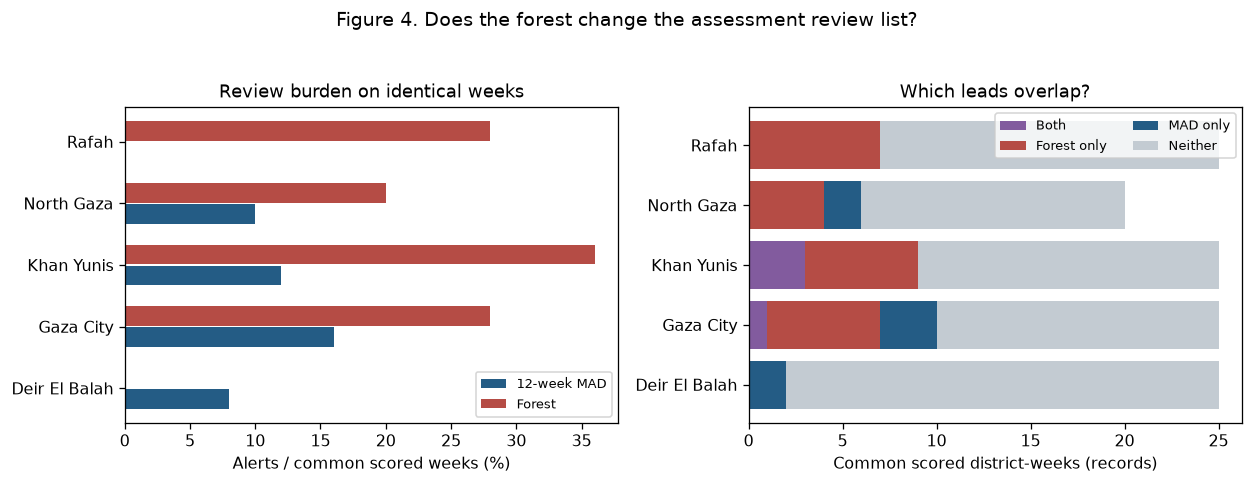

**Figure 4 and Tables 23-25 interpretation.** On 120 common district-weeks, the selected forest flags 27, the 12-week rule flags 11, and 4 overlap. There are 23 forest-only leads. Different burden or disagreement is not better detection: no independent labels tell us which leads merit review. Table 24 shows the actual feature values and baseline comparison; Table 25 and forest_example_records.csv retain documentary entries. The model learned from a short early block and its score distribution can drift; a tuning budget need not hold later.

In [7]:
if_rows=[]
for (district,name),spec in if_models.items():
    g=dw.loc[dw.admin2.eq(district)&dw.block.eq('assessment')].copy()
    finite=np.isfinite(g[spec['features']]).all(axis=1)
    eligible=g.history_eligible & finite
    anomaly=pd.Series(np.nan,index=g.index)
    anomaly.loc[eligible]=-spec['model'].score_samples(g.loc[eligible,spec['features']])
    assert spec['train_end']<spec['calibration_end']<g.week_start.min()
    for i,row in g.iterrows():
        if_rows.append({'admin2':district,'candidate':name,'week_start':row.week_start,'focal_events':row.focal_events,'political_events':row.political_events,'focal_share':row.focal_share,'previous_week_focal':row.previous_week_focal,'previous_four_weeks_focal':row.previous_four_weeks_focal,'eligible':bool(eligible.loc[i]),'reason':'scored' if eligible.loc[i] else ('partial current week' if not row.complete_week else 'ineligible current or lag history'),'anomaly_score':anomaly.loc[i],'cutoff':spec['cutoff'],'if_alert':bool(anomaly.loc[i]>spec['cutoff']) if eligible.loc[i] else False,'training_rows':spec['training_rows'],'train_end':spec['train_end'],'calibration_end':spec['calibration_end']})
if_scores=pd.DataFrame(if_rows)
if_scores.to_csv(OUT/'forest_assessment_scores.csv',index=False)
comparisons=[]; paired_all=[]
base=refcount.loc[refcount.block.eq('assessment'),['admin2','week_start','eligible','score','alert','direction','baseline','reason']].rename(columns={'eligible':'mad_eligible','score':'mad_score','alert':'mad_alert','reason':'mad_reason'})
for name,g in if_scores.groupby('candidate'):
    paired=g.merge(base,on=['admin2','week_start'],validate='one_to_one')
    paired['common']=paired.eligible & paired.mad_eligible
    paired_all.append(paired)
    for district,q in paired.groupby('admin2'):
        c=q.loc[q.common];union=(c.if_alert|c.mad_alert).sum()
        comparisons.append({'candidate':name,'admin2':district,'assessment_calendar_rows':len(q),'forest_scored':int(q.eligible.sum()),'mad_scored':int(q.mad_eligible.sum()),'common_scored':len(c),'forest_alerts':int(c.if_alert.sum()),'mad_alerts':int(c.mad_alert.sum()),'both':int((c.if_alert&c.mad_alert).sum()),'forest_only':int((c.if_alert&~c.mad_alert).sum()),'mad_only':int((c.mad_alert&~c.if_alert).sum()),'neither':int((~c.if_alert&~c.mad_alert).sum()),'alert_jaccard':(c.if_alert&c.mad_alert).sum()/union if union else np.nan})
if_comparison=pd.DataFrame(comparisons)
table(if_comparison.round(3),'Table 23: Forest versus MAD on common assessment weeks')
paired_all=pd.concat(paired_all,ignore_index=True)
paired=paired_all.loc[paired_all.candidate.eq(SELECTED_IF)&paired_all.common].copy()
assert paired.week_start.ge(ASSESS_START).all() and paired.week_start.le(weeks[-1]).all()
selected_comparison=if_comparison.loc[if_comparison.candidate.eq(SELECTED_IF)].copy()
totals=selected_comparison[['common_scored','forest_alerts','mad_alerts','both','forest_only','mad_only','neither']].sum()
print('Selected candidate assessment totals:',totals.to_dict())
if_examples=pd.concat([paired.loc[paired.if_alert & ~paired.mad_alert].nlargest(3,'anomaly_score').assign(category='Forest only'),paired.loc[paired.mad_alert].nlargest(2,'mad_score').assign(category='MAD flagged'),paired.loc[~paired.if_alert & ~paired.mad_alert].nlargest(2,'focal_events').assign(category='Neither; high raw count')],ignore_index=True)
table(if_examples[['category','admin2','week_start','focal_events','political_events','focal_share','previous_week_focal','anomaly_score','cutoff','mad_score','direction','baseline']].round(3),'Table 24: Forest comparison examples')
forest_traces=master.loc[master.focal_event].merge(if_examples[['admin2','week_start','category']].drop_duplicates(),on=['admin2','week_start'],validate='many_to_many')[['category','admin2','week_start','event_id_cnty','event_date','location','source','notes']]
forest_traces.to_csv(OUT/'forest_example_records.csv',index=False)
first=forest_traces.groupby(['category','admin2','week_start'],sort=False).head(1).copy();first['notes_excerpt']=first.notes.str.slice(0,150)
table(first.drop(columns='notes'),'Table 25: Forest documentary entry records')
fig,axes=plt.subplots(1,2,figsize=(11,4))
x=np.arange(len(selected_comparison));n=selected_comparison.common_scored.to_numpy()
axes[0].barh(x-.17,100*selected_comparison.mad_alerts/n,height=.32,color='#245c85',label='12-week MAD')
axes[0].barh(x+.17,100*selected_comparison.forest_alerts/n,height=.32,color='#b54c45',label='Forest')
axes[0].set(yticks=x,yticklabels=selected_comparison.admin2,xlabel='Alerts / common scored weeks (%)',title='Review burden on identical weeks');axes[0].legend(fontsize=8)
parts=[('both','Both','#825b9e'),('forest_only','Forest only','#b54c45'),('mad_only','MAD only','#245c85'),('neither','Neither','#c3cbd2')]
left=np.zeros(len(selected_comparison))
for col,label,color in parts:
    values=selected_comparison[col].to_numpy();axes[1].barh(x,values,left=left,color=color,label=label);left+=values
axes[1].set(yticks=x,yticklabels=selected_comparison.admin2,xlabel='Common scored district-weeks (records)',title='Which leads overlap?');axes[1].legend(fontsize=8,ncol=2)
fig.suptitle('Figure 4. Does the forest change the assessment review list?',y=1.04)
figure(fig,'Figure_4_forest_comparison')
report(f'**Figure 4 and Tables 23-25 interpretation.** On {int(totals.common_scored)} common district-weeks, the selected forest flags {int(totals.forest_alerts)}, the 12-week rule flags {int(totals.mad_alerts)}, and {int(totals.both)} overlap. There are {int(totals.forest_only)} forest-only leads. Different burden or disagreement is not better detection: no independent labels tell us which leads merit review. Table 24 shows the actual feature values and baseline comparison; Table 25 and forest_example_records.csv retain documentary entries. The model learned from a short early block and its score distribution can drift; a tuning budget need not hold later.')

**Decision: retain the median/MAD screen as the primary method; retain the forest comparison as experimental evidence only.** The forest supplies different candidates but does not establish added documentary value or superiority. Its small per-district training sets, changing activity levels and lack of independent review labels do not justify operational replacement. The transparent rule exposes the local baseline and direction directly. An independent reviewer can assess both lists before deciding whether the extra method is useful; precision/recall are deferred until suitable labels exist.

## S7. What should a documentation team take from these screens?

### Answers to the five business questions

| Question | Answer and evidence |
|---|---|
| BQ1: change before and after October 7, 2023 | Phase 3's descriptive comparison remains the answer. Phase 4 deliberately models the post-cutoff Gaza land cohort; its clusters and local screens cannot estimate the before/after change or the West Bank. See Phase 3 Task 6. |
| BQ2: actors and event types | Phase 3's coded actor/event cross-tabs and incident notes remain the answer. Phase 4 uses the exact focal flag and retains source IDs/notes for review; it does not infer an actor's intent or role. See Phase 3 Task 6 and Phase 4 Table 10. |
| BQ3: geographic concentrations | Among 10,583 post-cutoff land focal records at 101 coordinate pairs, the descriptive 1 km/50 DBSCAN reference groups recorded places within districts (Tables 5, 8-10; Figure 2). Gaza City has 3,436 records in the district baseline (Table 8). The largest displayed group has 852 records across four coordinate pairs, mainly Gaza - Shujaiyya (Table 9). Repeated and approximate coordinates make these concentrations of *recorded places*, not measured incident footprints. Nearby radii and the precision-1 restriction change memberships (Tables 6-7). |
| BQ4: unusual district-weeks | Earlier-only 8/12/16-week median/MAD screens score 465/441/417 district-weeks and flag 48/34/22, respectively (Table 18). The 8-versus-16 overlap is 14 of 54 weeks flagged by either setting among common scored weeks (Table 14). Table 17 gives traceable high, low and ordinary examples; Figure 3 keeps gaps visible. These are review leads relative to prior local records, not verified anomalies. |
| BQ5: sensitivity | The spatial candidate grid changes group and noise counts (Tables 5-7); the narrower temporal window produces more flags (Tables 14 and 18). The forest comparison uses the same assessment weeks but yields different candidates (Table 23; Figure 4). Neither method has independent review labels. The historical snapshot was already explored in Phase 3, so even the later chronological block is retrospective. |

### What each method contributes

| Method | Population and retained setting | Simple comparison and evaluation | Practical use and limit |
|---|---|---|---|
| DBSCAN | 10,583 post-cutoff Gaza land focal records; 1 km radius/50 records is a descriptive reference, alongside the full radius/density grid and precision-1 check (Tables 4-7) | District totals (Table 8); group/noise sizes, sampled non-noise haversine silhouette, nearby-setting and common-ID membership comparisons (Tables 5-7) | Names nearby recorded places within a district for source review (Table 9, Figure 2). Coordinate repetition, imprecise locations and radius sensitivity limit geographic inference. |
| Median/MAD | Complete district-weeks with positive political denominator and intact earlier calendar history; 12-week reference, with 8/16-week sensitivity (Tables 12-20) | Raw count/share and earlier local baseline; common-week coverage, burden, overlap, peaks and rebounds (Tables 13-20, Figure 3) | Produces explainable high and low review leads. Short history, changing reporting and no labels limit interpretation. |
| Isolation Forest, experimental | District-specific earlier-only fits; frozen two-feature, 32-sample candidate and tuning-derived cutoffs (Tables 21-25) | Same assessable assessment weeks as 12-week MAD, with overlap and traced examples (Table 23, Figure 4) | Offers a second candidate list, but added documentary value is unverified. Keep MAD as the primary screen. |

Metrics across these rows answer different questions; their values do not form a ranking. Tables 10 and 25 retain source examples, while the complete assignments and scores are saved under `task4 tasks/implementation/` for audit. A reviewer should follow an event ID to its note and source, confirm place/date coding and compare independent records before drawing a substantive conclusion.

### Recommendations

1. Start a place-based source review with the largest and persistent groups in Table 9, using the district baseline in Table 8 and map in Figure 2 for context. Sample both precise and coarser coded locations, and check whether repeated coordinates represent distinct recorded events.
2. Review completed district-weeks that the 12-week screen flags across multiple window lengths (Tables 14, 17-18). Read the raw focal count, political denominator, share, earlier median and event notes together; do not treat the flag as a finding.
3. Keep a separate small sample of window-specific flags, rebound weeks and ordinary comparison weeks (Tables 17, 19-20). This tests whether the screening rule is useful across changing local activity instead of selecting only dramatic peaks.
4. Have independent documentation reviewers record a consistent disposition and reasons for a bounded sample from the MAD and forest lists (Tables 23-25). Compare their usefulness only after such labels exist; do not automate attribution or intervention from these screens.

**Limits and next evidence.** ACLED coverage and coding depend on reporting and access; absence of a record is not absence of an event. The focal definition selects an exact coded civilian label, and land/precision restrictions further change who enters the spatial analysis. Rounded or repeated coordinates, district aggregation, time dependence, short eligible histories, undefined shares and the incomplete final week constrain the results. No independent truth labels, on-site verification or untouched future data are available. The next defensible evaluation needs a newly collected period and documented human review, with settings fixed beforehand.

**Sources.** ACLED event data and codebook (source dataset); DS312 Phase 1 business questions, Phase 2 preprocessing/provenance and Phase 3 data guide, Task 6 and Task 7; DS312 final PIT guide, pp. 5-6; Menorias, *Module 7 DS312 Cluster Analysis*, §§7.4–7.6, and *Module 9 Anomaly Detection*, §§3–6; scikit-learn DBSCAN, silhouette and IsolationForest documentation; pandas and NumPy documentation. S2 and the recorded runtime specify the local input files and package versions.